In [15]:
from datetime import date

today = date.today()
print(f'Last full compilation {today}')

Last full compilation 2023-06-19


In [16]:
from classes import *
from funcData import *
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from math import *
from math_func import *

import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 100

C=list(plt.cm.plasma([0.0, 0.2  ]))+[ 'crimson', 'darkorange', 'steelblue', 'yellowgreen']

campagnes = ['campagne_r0']
# Can be long the first time
data=read_data_from_campaigns(campagnes)
data_bulk = get_bulk_data(data)

Lecture des données réalisée en 0.00138s


r0_2
1.3774532699443978
1.9819588922391222


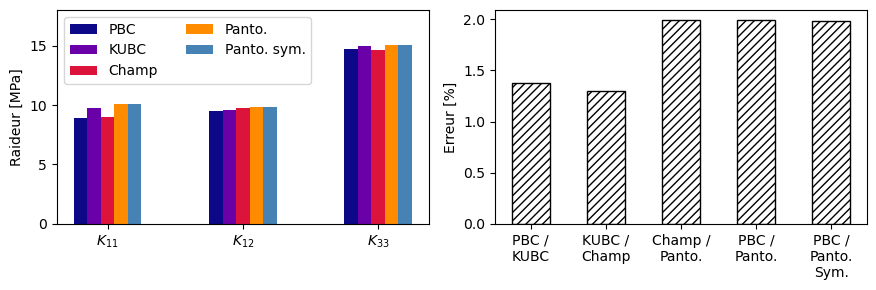

In [17]:
test=data_bulk['r0_2']
print(test.test_id)

plt.figure(figsize=(9,3))
plt.subplot(121)
width=0.1
x=np.linspace(0,2,3)
plt.bar(x-0.2,[test.K_plane_stress_PBC[0][0],test.K_plane_stress_PBC[1][0],test.K_plane_stress_PBC[2][2]],
        width, color=C[0], label='PBC')
plt.bar(x-0.1,[test.K_plane_stress_KUBC[0][0],test.K_plane_stress_KUBC[1][0],test.K_plane_stress_KUBC[2][2]],
        width, color=C[1], label='KUBC')
plt.bar(x+0.0,[test.K_field_dic[0][0],test.K_field_dic[1][0],test.K_field_dic[2][2]],
        width, color=C[2], label='Champ')
plt.bar(x+0.1,[test.K_panto_dic[0][0],test.K_panto_dic[1][0],test.K_panto_dic[2][2]],
        width, color=C[3],  label='Panto.')
k_sym=get_sym_part(test.K_panto_dic)
plt.bar(x+0.2,[k_sym[0][0],k_sym[1][0],k_sym[2][2]],
        width, color=C[4],  label='Panto. sym.')

plt.legend(loc='upper left', ncol=2)
plt.ylabel('Raideur [MPa]')
plt.ylim(top=18)
plt.xticks(range(3), [r'$K_{11}$',r'$K_{12}$',r'$K_{33}$'])



plt.subplot(122)
width=0.5
x=np.linspace(0,4,5)



plt.bar(0,[test.get_error((0,1))],
        width, color='None',edgecolor='k', hatch="////")
print(test.get_error((0,1)))
plt.bar(1,[test.get_error((1,2))],
        width, color='None',edgecolor='k', hatch="////")
plt.bar(2,[test.get_error((2,3))],
        width, color='None',edgecolor='k', hatch="////")
plt.bar(3,[test.get_error((0,3))],
        width, color='None',edgecolor='k', hatch="////")
plt.bar(4,[get_error_custom(np.array(test.K_plane_stress_PBC),get_sym_part(test.K_panto_dic))],
        width, color='None',edgecolor='k', hatch="////")
print(get_error_custom(np.array(test.K_plane_stress_PBC),get_sym_part(test.K_panto_dic)))

plt.ylabel('Erreur [%]')
plt.xticks(range(5), ['PBC /\nKUBC',
                      'KUBC /\nChamp',
                      'Champ /\nPanto.',
                      'PBC /\nPanto.','PBC /\nPanto.\nSym.'])
plt.tight_layout()
plt.savefig('images/err_ro_coef.pdf')

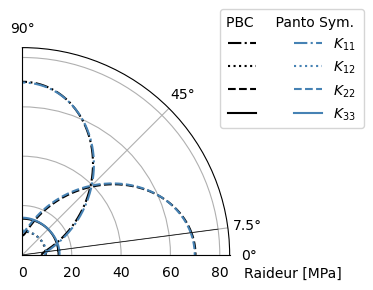

In [18]:



K_0 = np.array(test.K_plane_stress_PBC)

plt.subplots(subplot_kw={'projection': 'polar'},figsize=(5,3))
offset=7.5

K_list = []
theta_list = np.arange(0, 2*pi, pi/1000)

for t in theta_list:
    angle = t
    c, s = cos(angle), sin(angle)
    T = np.array([[c**2, s**2, c*s],
                [s**2, c**2, -c*s],
                [-2*s*c, 2*c*s, (c**2-s**2)]])
    K = np.dot(np.dot(np.transpose(T), K_0), T)
    K_list.append(K)


K_list = np.array(K_list)
coeff=((0,0),(1,0),(1,1),(2,2))
style=['-.', ':', '--', '-']
for c_i,c in enumerate(coeff):
    plt.plot(theta_list+offset/180*pi, K_list[:, c[0], c[1]],style[c_i], color='k',label=r'$K_3$       ')

# * * * * * * * * * *
K_0 = np.array(test.K_panto_dic)
K_list = []
theta_list = np.arange(0, 2*pi, pi/1000)

for t in theta_list:
    angle = t
    c, s = cos(angle), sin(angle)
    T = np.array([[c**2, s**2, c*s],
                [s**2, c**2, -c*s],
                [-2*s*c, 2*c*s, (c**2-s**2)]])
    K = np.dot(np.dot(np.transpose(T), K_0), T)
    K_list.append(K)


K_list = np.array(K_list)
coeff=((0,0),(1,0),(1,1),(2,2))
style=['-.', ':', '--', '-']
coeff_name=[r'$K_{11}$',r'$K_{12}$',r'$K_{22}$',r'$K_{33}$']
for c_i,c in enumerate(coeff):
    plt.plot(theta_list+offset/180*pi, K_list[:, c[0], c[1]],style[c_i],color=C[4] ,label=coeff_name[c_i])

# * * * * * * * *
plt.plot([offset/180*pi]*2,[0,80],'k-',lw=0.5)

ax=plt.gca()
ax.set_thetagrids((0,7.5,45,90,135,180,225,270,315),[f'{i}°' for i in [0,7.5,45,90,135,180,225,270,315]])
ax.get_yaxis().set_major_formatter(mpl.ticker.ScalarFormatter())

# ax.set_rticks([20,40,60,80])
# ax.set_rlabel_position(-22.5)  


l=plt.legend(title='PBC     Panto Sym. ',ncol=2,columnspacing=-1.2,
           loc='center left', bbox_to_anchor=(0.92, 0.9))
# plt.ylim((0,80))

ax.set_thetamin(0)
ax.set_thetamax(90)

plt.text(-0.05,90, 'Raideur [MPa]', va='top')
for text in l.get_texts()[:4]:
    text.set_color("white")
plt.tight_layout()
plt.savefig('images/r0_polar.pdf')

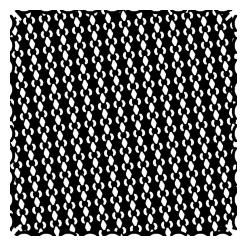

In [19]:
test.show_geo()

In [20]:

# * On décide maintenant de prendre 4 essais à 7.5° et 10°

test_1 = data_bulk['r0_1']
test_2 = data_bulk['r0_2']
test_3 = data_bulk['r0_3']
test_4 = data_bulk['r0_4']
test_list = [test_1,test_2,test_3,test_4]

K_PBC = np.array(test_1.K_plane_stress_PBC)
K_panto_1 = np.array(test_1.K_panto_dic)
K_panto_2 = np.array(test_2.K_panto_dic)
K_panto_3 = np.array(test_3.K_panto_dic)
K_panto_4 = np.array(test_4.K_panto_dic)

# On tourne les matrices qui sont à 10° de -2.5° pour les comparer à 7.5°
K_panto_3 = rotation_voigt(K_panto_3, -2.5*pi/180)
K_panto_4 = rotation_voigt(K_panto_4, -2.5*pi/180)

print('Erreur individuelle test par test')
for t in test_list:
    print(t.get_error((0,3)))


print('Erreur en faisant la moyenne des tests')
k_mean = get_sym_part((K_panto_1+K_panto_2+K_panto_3+K_panto_4) / 4)
mean_err = get_error_custom(K_PBC, k_mean)
print(mean_err)


Erreur individuelle test par test
1.7209759466425725
1.992065896333839
1.89896649332897
2.039457293967272
Erreur en faisant la moyenne des tests
1.8370523814761175


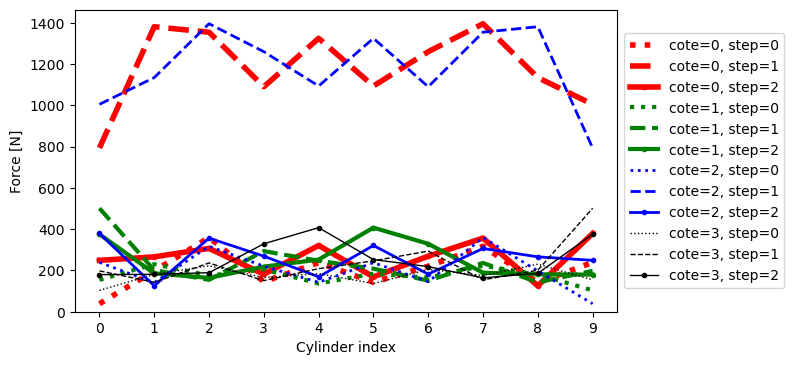

In [21]:
def get_norm(x, y) -> float:
    return sqrt(x**2+y**2)

def plot_forces(test):
    time_step, extracted_disp_and_force = test.get_forces()
    rf = extracted_disp_and_force['TBC']

    rf_norm = np.zeros((4, 10, 3))
    for cote in range(4):
        for cyl in range(10):
            if len(rf[cote*12*4+cyl*12]) != 0:
                rf_norm[cote, cyl, :] = np.array([get_norm(rf[cote*12*10+cyl*12][1], rf[cote*12*10+cyl*12+1][1]),
                                        get_norm(rf[cote*12*10+cyl*12][2], rf[cote*12*10+cyl*12+1][2]),
                                        get_norm(rf[cote*12*10+cyl*12][3], rf[cote*12*10+cyl*12+1][3])])

    plt.figure(figsize=(7,4))
    color=['r', 'g', 'b', 'k']
    style=[':', '--', '.-']
    for cote in range(4):
        for step in range(3):
            plt.plot(range(10), rf_norm[cote, :, step], color[cote]+style[step], label=f'{cote=}, {step=}', lw=4-cote)
    plt.xlabel('Cylinder index')
    plt.ylabel('Force [N]')
    plt.xticks(range(10))
    plt.ylim(bottom=0)
    plt.legend()
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plot_forces(data_bulk['r0_1'])

In [22]:

# * Calcul du R0

k_ref = np.array(test_1.K_panto_dic[:])
k_ref=0.5*(k_ref+np.transpose(k_ref))

R0 = sqrt((k_ref[0,0] - 2*k_ref[0,1] -4* k_ref[2,2] + k_ref[1,1])**2+
          (4*(k_ref[2,0]-k_ref[2,1]))**2)


print(R0/norme(k_ref))

0.023725259816407395


In [23]:
from classes import *
from funcData import *
import numpy as np
import matplotlib.pyplot as plt
from math import *
import os 

campagnes = ['campagne_carre']
# Can be long the first time
data = get_bulk_data(read_data_from_campaigns(campagnes))

tmp = data['carre_10_4_2_5']
print(tmp.get_error((0,3)))

k_ref = np.array(tmp.K_plane_stress_PBC)
k_ref=0.5*(k_ref+np.transpose(k_ref))

R0 = sqrt((k_ref[0,0] - 2*k_ref[0,1] -4* k_ref[2,2] + k_ref[1,1])**2+
          (4*(k_ref[2,0]-k_ref[2,1]))**2)
print(R0/norme(k_ref))


Lecture des données réalisée en 0.58944s
2.579318642321729
1.2045491018027246


In [2]:
from classes import *
from funcData import *
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from math import *
from math_func import *
from time import perf_counter

import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 100

C=list(plt.cm.plasma([0.0, 0.2  ]))+[ 'crimson', 'darkorange', 'steelblue', 'yellowgreen']

campagnes = ['campagne_r0']
# Can be long the first time
data=read_data_from_campaigns(campagnes)
data_bulk = get_bulk_data(data)


d=data_bulk['r0_1'].get_exportable_dict_with_img()


Lecture des données réalisée en 0.00223s
0.13385498199932044
